In [104]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
from utils import paths
import os
import dask.dataframe as dd

/opt/anaconda3/lib/python3.11/site-packages/dask/array/chunk_types.py:131: UserWarning: A NumPy version >=1.25.2 and <2.6.0 is required for this version of SciPy (detected version 1.24.4)
  import scipy.sparse


In [248]:
#make a dictionary with the dataframes of all the places
dfs = {}

for file in glob.glob(os.path.join(paths.FLUXNET_DD_DIR, "*.csv")):
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    timestamp = pd.to_datetime(df["TIMESTAMP"], format="%Y%m%d")
    timestamp.name = "TIMESTAMP"
    #checks only for swc, make it so it works for other variables as well
    try:
        df2 = pd.concat([timestamp , df["LE_F_MDS"], df["SWC_F_MDS_1"], df["TA_F"], df["TS_F_MDS_1"], df["WS_F"]], axis=1)
        df2['SWC_F_MDS_1'] = df2['SWC_F_MDS_1'].replace(-9999, np.nan).dropna(axis = 0)
        df2['WS_F'] = df2['WS_F'].replace(-9999, np.nan).dropna(axis = 0)
        df2["TS_F_MDS_1"] = df2["TS_F_MDS_1"].replace(-9999, np.nan).dropna(axis = 0)
    except: KeyError
        #
        #df2 = pd.concat([timestamp , df["LE_F_MDS"], df["SWC_F_MDS_1"]], axis=1)
    df2["ET"] = df2["LE_F_MDS"] / 2540000
    df2["ET_mmPerDay"] = df2["ET"] * 86400
    dfs[os.path.basename(file).split(".")[0]] = df2

/Users/pavan/Documents/ERICA RESEARCH/testing/dir_fluxnet_dd_selected/CN-Cha.csv
Index(['TIMESTAMP', 'LE_F_MDS', 'SWC_F_MDS_1', 'TA_F', 'TS_F_MDS_1', 'WS_F'], dtype='object')
/Users/pavan/Documents/ERICA RESEARCH/testing/dir_fluxnet_dd_selected/AU-ASM.csv
Index(['TIMESTAMP', 'LE_F_MDS', 'SWC_F_MDS_1', 'TA_F', 'TS_F_MDS_1', 'WS_F'], dtype='object')
/Users/pavan/Documents/ERICA RESEARCH/testing/dir_fluxnet_dd_selected/US-Goo.csv
Index(['TIMESTAMP', 'LE_F_MDS', 'SWC_F_MDS_1', 'TA_F', 'TS_F_MDS_1', 'WS_F'], dtype='object')
/Users/pavan/Documents/ERICA RESEARCH/testing/dir_fluxnet_dd_selected/US-Wi2.csv
Index(['TIMESTAMP', 'LE_F_MDS', 'SWC_F_MDS_1', 'TA_F', 'TS_F_MDS_1', 'WS_F',
       'ET', 'ET_mmPerDay'],
      dtype='object')
/Users/pavan/Documents/ERICA RESEARCH/testing/dir_fluxnet_dd_selected/IT-Tor.csv
Index(['TIMESTAMP', 'LE_F_MDS', 'SWC_F_MDS_1', 'TA_F', 'TS_F_MDS_1', 'WS_F'], dtype='object')
/Users/pavan/Documents/ERICA RESEARCH/testing/dir_fluxnet_dd_selected/US-Wi3.csv
Index(['TI

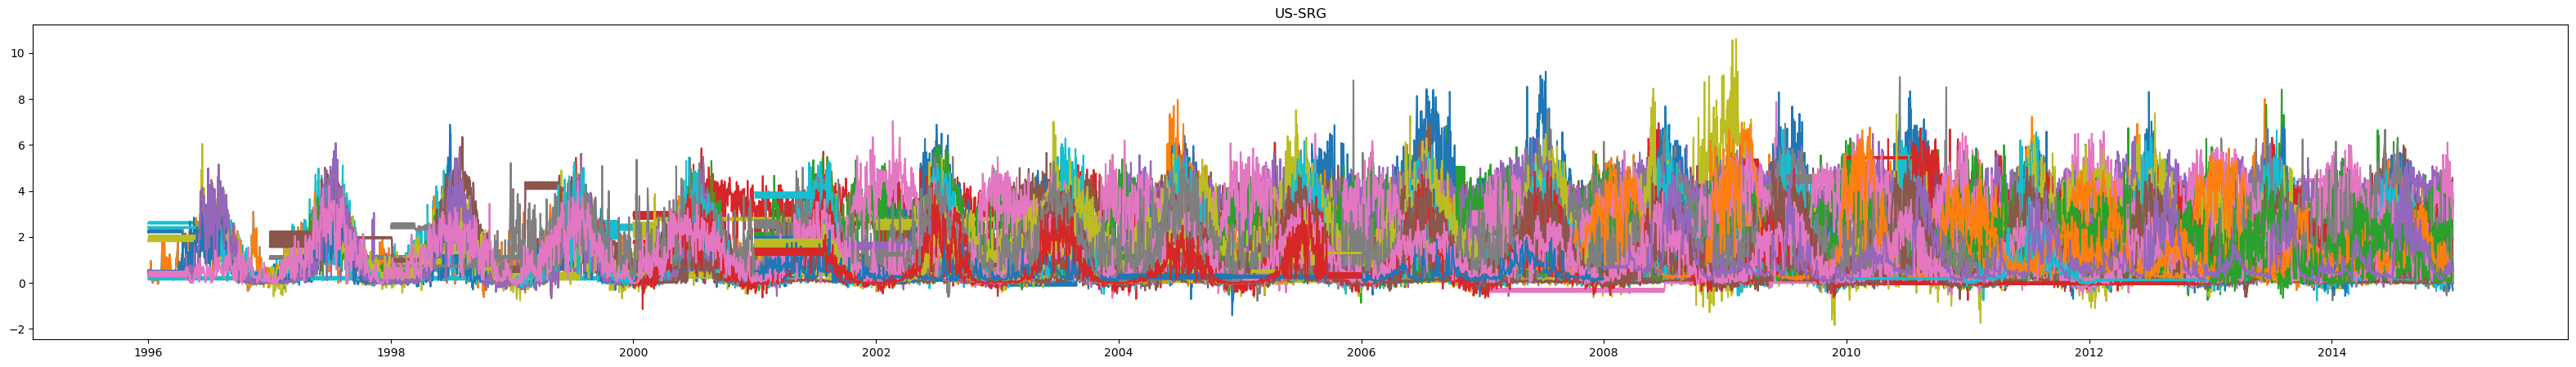

In [268]:
#time series plot for evapotranspiration
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for name, df in dfs.items():
    plt.plot(df["TIMESTAMP"], df["ET_mmPerDay"])
    plt.title(name)

plt.show()

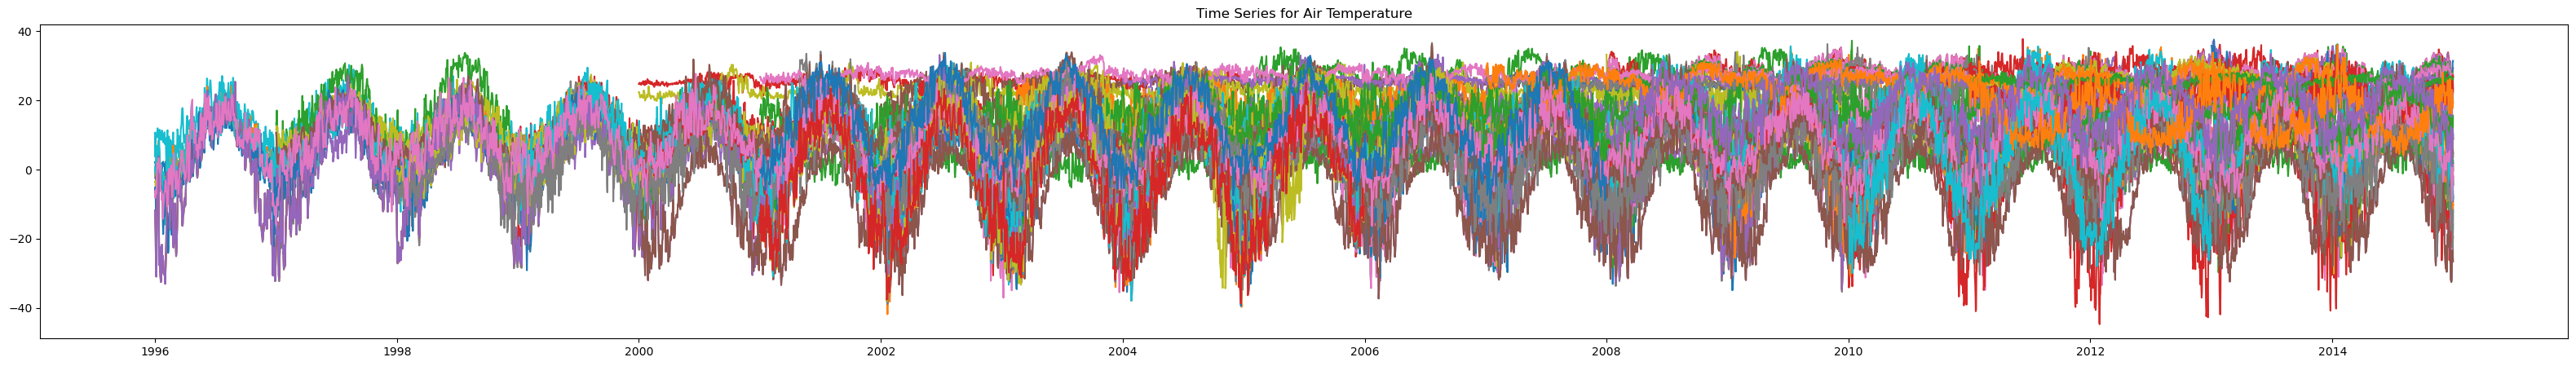

In [270]:
#time series for air temp
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for name, df in dfs.items():
    plt.plot(df["TIMESTAMP"], df["TA_F"])
    plt.title("Time Series for Air Temperature")

plt.show()

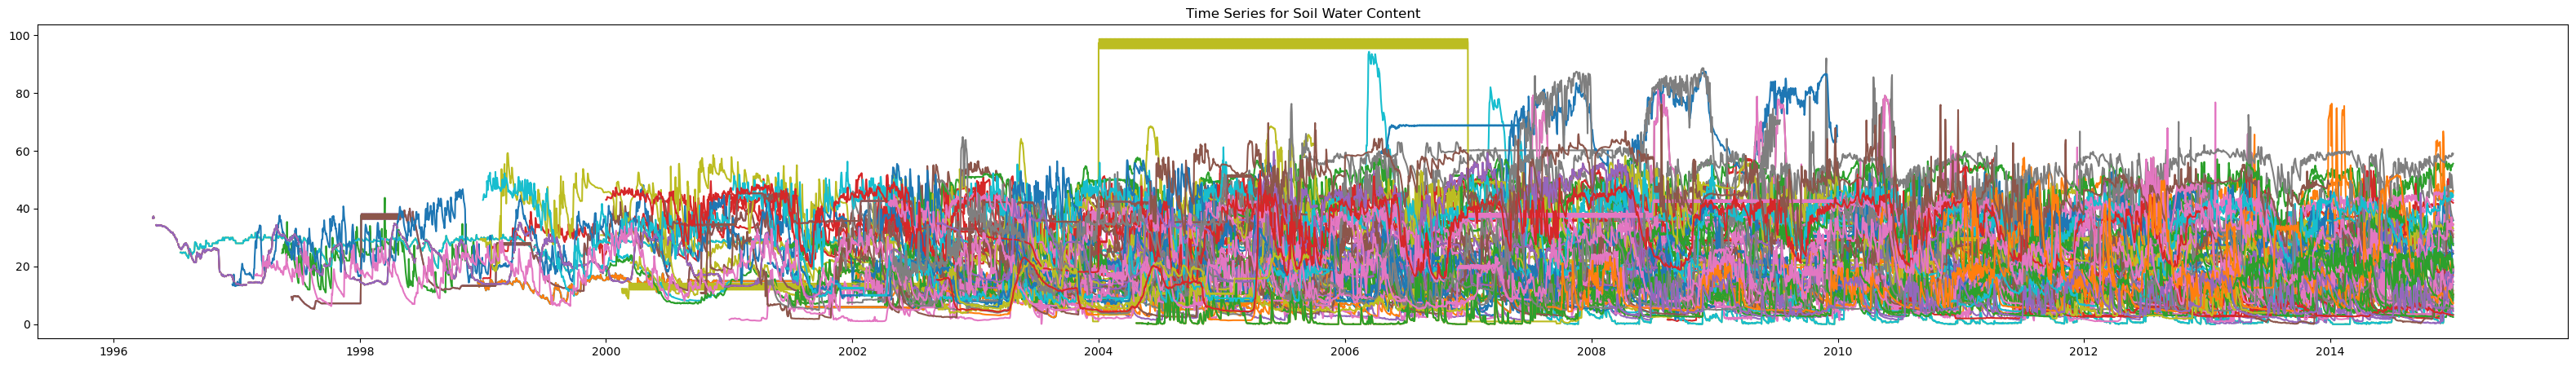

In [272]:
#time series plot for soil water content (removed missing values)
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for name, df in dfs.items():
    plt.plot(df["TIMESTAMP"], df["SWC_F_MDS_1"])
    plt.title("Time Series for Soil Water Content")

plt.show()

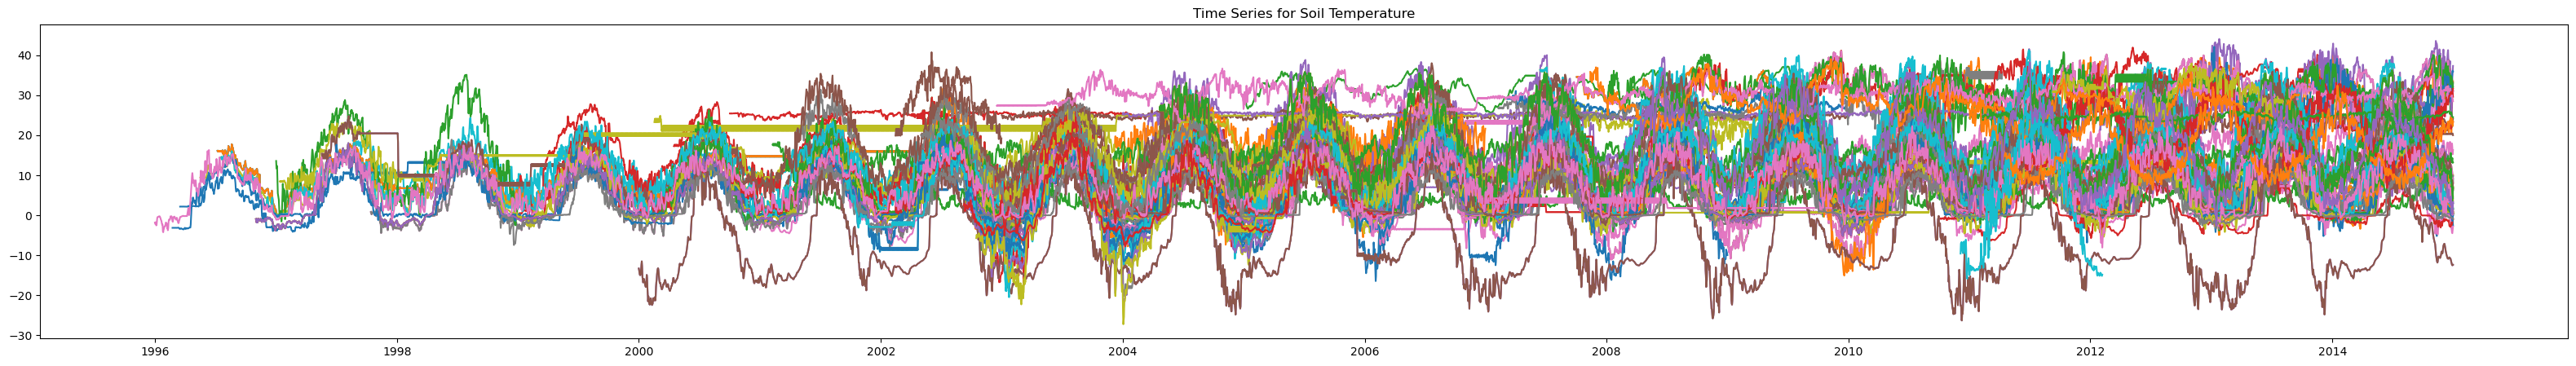

In [274]:
#time series plot for soil temperature (removed missing values)
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for name, df in dfs.items():
    plt.plot(df["TIMESTAMP"], df["TS_F_MDS_1"])
    plt.title("Time Series for Soil Temperature")

plt.show()

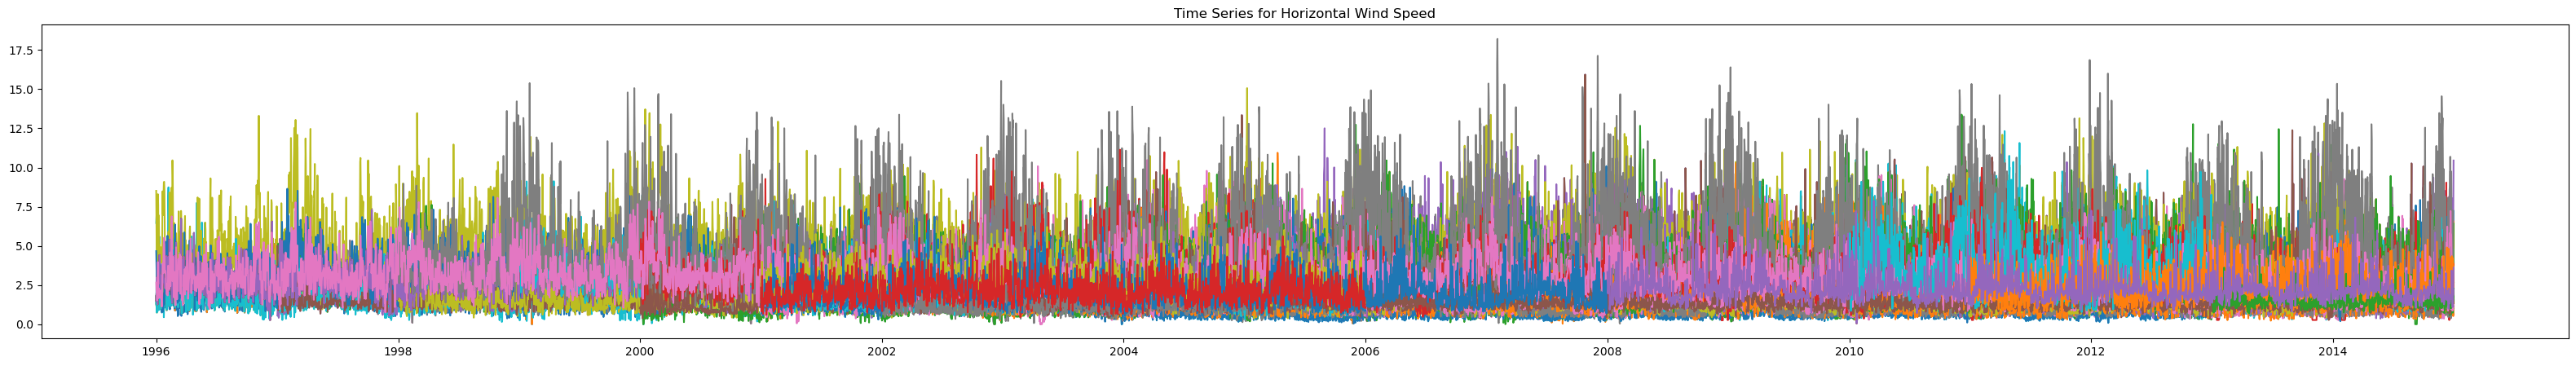

In [276]:
#time series plot for horizontal wind speed (removed missing values)
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for name, df in dfs.items():
    plt.plot(df["TIMESTAMP"], df["WS_F"])
    plt.title("Time Series for Horizontal Wind Speed")

plt.show()

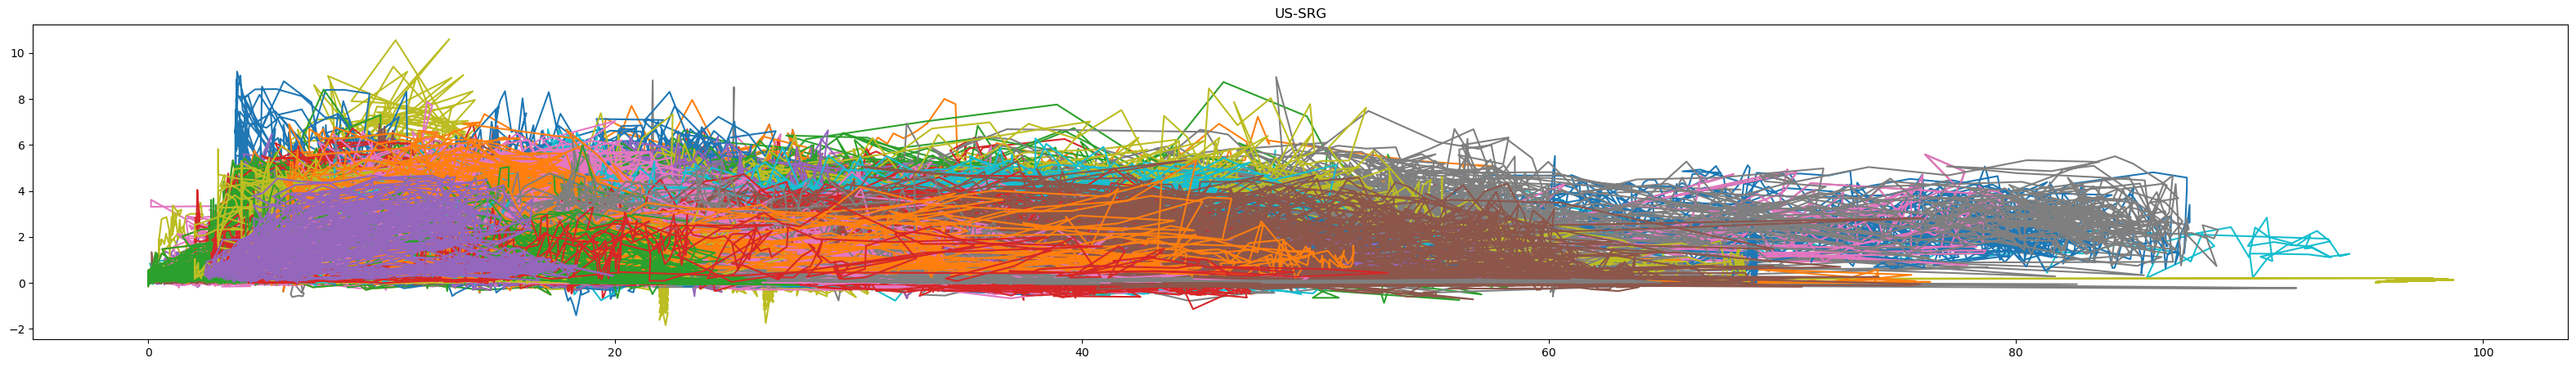

In [266]:
#time series plot for soil water content (removed missing values)
import matplotlib.pyplot as plt
plt.figure(figsize=(40,5))

for name, df in dfs.items():
    plt.plot(df["SWC_F_MDS_1"], df["ET_mmPerDay"])
    plt.title(name)

plt.show()

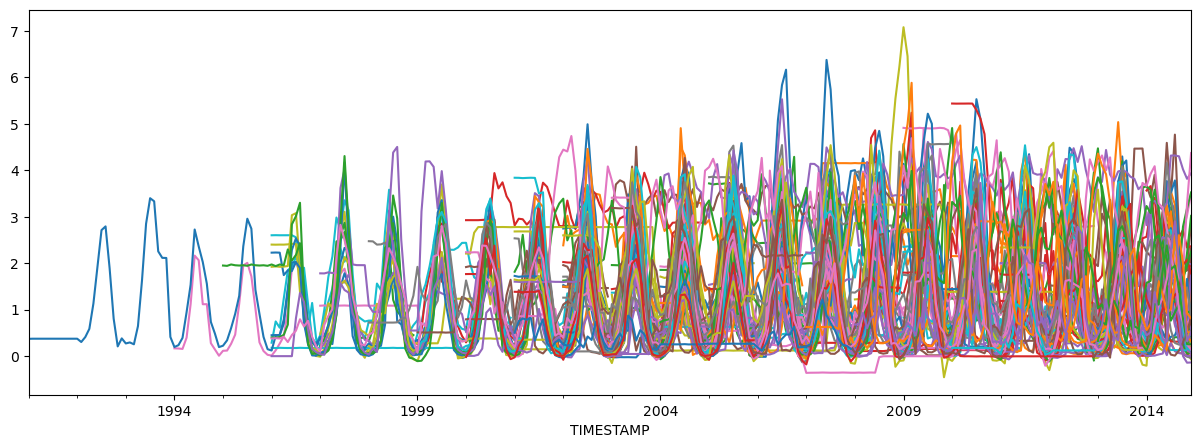

In [27]:
#time series for air temperature, mean 
plt.figure(figsize=(15,5))

for name, df in dfs.items():
    df = df.set_index("TIMESTAMP")
    monthly_avg = df["ET_mmPerDay"].resample("M").mean()
    monthly_avg.plot(marker="", label=name)

plt.show()
